In [9]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

In [10]:
load_dotenv()

True

In [12]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

In [13]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [14]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str

In [15]:
llm = ChatOpenAI(model="gpt-4.1-mini")

In [16]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}

In [17]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

In [18]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [19]:
from pathlib import Path

def reducer(state: State) -> dict:
    
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    # ---- save to file ----
    filename = title.lower().replace(" ", "_") + ".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}


In [20]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

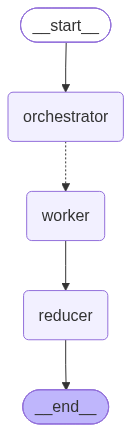

In [21]:
g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app

In [30]:
# Run your agent
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})

# Extract the blog content (adjust the key based on your state)
blog_content = "\n\n".join(out.get("sections", []))

# Write the content to the file
with open("understanding_self-attention.md", "w", encoding="utf-8") as f:
    f.write(blog_content)

In [27]:
# import pprint
# pprint.pprint(out)
# print(out['plan'])

{'final': '# Understanding Self-Attention: The Backbone of Modern AI Models\n'
          '\n'
          '## Introduction to Self-Attention\n'
          '\n'
          'Self-attention is a powerful mechanism in machine learning that '
          'allows models to weigh the importance of different parts of input '
          'data relative to each other. Unlike traditional approaches that '
          'process data sequentially or focus on local context, self-attention '
          'evaluates relationships within the entire sequence simultaneously. '
          'This capability enables models to capture long-range dependencies '
          'and contextual nuances more effectively.\n'
          '\n'
          'In natural language processing (NLP), self-attention plays a '
          'crucial role in understanding the semantics of sentences, where the '
          'meaning of a word often depends on other words in the context, '
          'sometimes far away in the text. By dynamically assigning a